In [1]:
!wget -q -nc https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig2-six-metric-rank-snapshot-20261117.tar.gz
!git clone -q --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git
%pip install -q numpy pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


**Historical coordinates only. These rankings do not evaluate the newer agent-assisted selected OmniAligner runs.**

# Fig. 2 additional six-metric ranking — completed snapshot
Three datasets have finished five methods. OmniAligner is rankable on 12 endpoints across SmallIntestine and STARmap, with **0 first places**. ST_brain OmniAligner endpoints are excluded for insufficient overlap/fallback or undefined values. Six datasets are pending and not ranked.

This notebook recomputes **qualification, ranks and the figure from archived method means**, not metrics from raw coordinates. The six-dataset NCS submission table is a different experiment and is unchanged. Original Fig. 2 methods here include Loki. Scores retain full precision. Figures are standalone.


In [2]:
from pathlib import Path
import hashlib, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
archive = Path('rev1-fig2-six-metric-rank-snapshot-20261117.tar.gz')
assert hashlib.sha256(archive.read_bytes()).hexdigest() == 'bba6affbb07310fba7808431e0db8b1420e60854a08718fd0f0b20fe25a62df2'
with tarfile.open(archive) as bundle:
    for member in bundle.getmembers():
        assert not Path(member.name).is_absolute() and '..' not in Path(member.name).parts
    bundle.extractall('.')
root = Path('fig2_rank_snapshot')
means = pd.read_csv(root / 'all_native_means_diagnostic.csv')
metrics = ['PCC', 'CosSim', 'SSIM', 'MI', 'MSE', 'Region']
datasets = ['SmallIntestine', 'STARmap', 'ST_brain']
display(means)


,PCC,CosSim,SSIM,MI,MSE,Region,dataset,method,pairs_completed,pairs_expected,eligible,status
0,0.562523,0.912313,0.554475,0.309127,0.027779,0.779062,SmallIntestine,STalign,7,7,True,complete
1,0.583542,0.916624,0.575067,0.331339,0.024748,0.845327,SmallIntestine,loki,7,7,True,complete
2,0.662555,0.934111,0.648870,0.385760,0.021223,0.908041,SmallIntestine,SPACEL,7,7,True,complete
3,0.636393,0.928781,0.624615,0.359866,0.022408,0.854055,SmallIntestine,spateo,7,7,True,complete
4,0.613732,0.924764,0.601777,0.351662,0.023200,0.883842,SmallIntestine,omnialigner,7,7,True,complete
5,-0.079307,0.984516,0.028349,0.067980,1.564698,0.333525,STARmap,STalign,9,9,True,complete
6,0.201184,0.988833,0.286188,0.436011,1.137163,0.503385,STARmap,loki,9,9,True,complete
7,0.884341,0.998493,0.897036,0.777650,0.197342,0.946470,STARmap,SPACEL,9,9,True,complete
8,0.828877,0.997510,0.846722,0.731263,0.268806,0.930806,STARmap,spateo,9,9,True,complete
9,0.850504,0.998097,0.865031,0.740479,0.246204,0.936042,STARmap,omnialigner,9,9,True,complete


## Eligibility and ranking
Ranks are 1 + the number of strictly better eligible method means, so exact ties share rank. MSE is lower-is-better; other metrics are higher-is-better. Whole-sequence means must include all expected pairs.

For this interim matrix the conservative archived condition-level eligibility flag is used. ST_brain OmniAligner is excluded on all six endpoints: pairs 64/70 have no overlap support and native molecular defaults; pair 68 additionally has an undefined gene score. Native diagnostic defaults are preserved in the input CSV, never substituted as valid performance. This flag also excludes STalign's ST_brain molecular fallback. Endpoint-specific evaluations require their accompanying pair-support audit, rather than ranking finite defaults.


In [3]:
rank_rows = []
for dataset in datasets:
    subset = means[means['dataset'] == dataset].copy()
    for metric in metrics:
        complete = subset['pairs_completed'].eq(subset['pairs_expected'])
        eligible = subset['eligible'].astype(str).str.lower().eq('true')
        valid = subset[complete & eligible & np.isfinite(subset[metric])]
        omni = valid[valid['method'] == 'omnialigner']
        rank = np.nan
        if len(omni) == 1:
            value = omni.iloc[0][metric]
            better = valid[metric] < value if metric == 'MSE' else valid[metric] > value
            rank = 1 + int(better.sum())
        rank_rows.append(dict(dataset=dataset, metric=metric, rank=rank,
                              algorithm_count=len(valid) if np.isfinite(rank) else np.nan))
ranks = pd.DataFrame(rank_rows)
ranks['display'] = ranks.apply(lambda r: f"{int(r['rank'])}/{int(r['algorithm_count'])}" if pd.notna(r['rank']) else '—', axis=1)
expected = pd.read_csv(root / 'Fig2_new_metrics_OmniAligner_ranks.csv')
assert ranks['display'].tolist() == expected['display'].tolist()
first = int(ranks['rank'].eq(1).sum())
rankable = int(ranks['rank'].notna().sum())
assert (first, rankable) == (0, 12)
display(ranks.pivot(index='dataset', columns='metric', values='display').reindex(index=datasets, columns=metrics))
print(f'OmniAligner first: {first}/{rankable} rankable endpoints; 18/18 snapshot cells matched.')


metric,PCC,CosSim,SSIM,MI,MSE,Region
dataset,,,,,,
SmallIntestine,3/5,3/5,3/5,3/5,3/5,2/5
STARmap,2/5,2/5,2/5,2/5,2/5,2/5
ST_brain,—,—,—,—,—,—


OmniAligner first: 0/12 rankable endpoints; 18/18 snapshot cells matched.


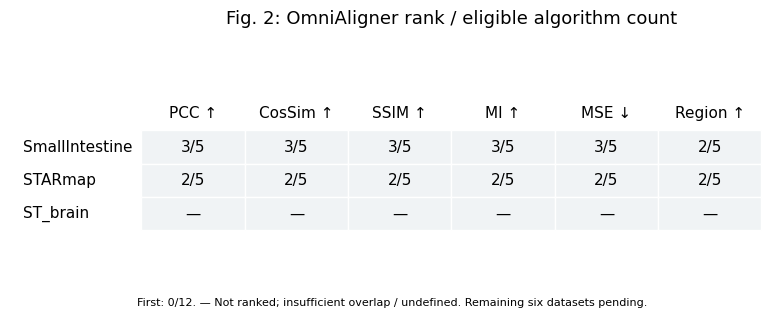

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.axis('off')
labels = ranks.pivot(index='dataset', columns='metric', values='display').reindex(index=datasets, columns=metrics)
colors = [['#D1E8DE' if value.startswith('1/') else '#F0F3F5' for value in row] for row in labels.values]
table = ax.table(cellText=labels.values, rowLabels=datasets,
                 colLabels=[m + (' ↓' if m == 'MSE' else ' ↑') for m in metrics],
                 cellColours=colors, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)
for cell in table.get_celld().values():
    cell.set_edgecolor('white')
ax.set_title('Fig. 2: OmniAligner rank / eligible algorithm count', fontsize=13, pad=12)
fig.text(.12, .05, f'First: {first}/{rankable}. — Not ranked; insufficient overlap / undefined. Remaining six datasets pending.', fontsize=8)
output = Path('fig2_rank_outputs'); output.mkdir(exist_ok=True)
ranks.to_csv(output / 'OmniAligner_ranks.csv', index=False)
means.to_csv(output / 'native_diagnostic_means.csv', index=False)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
for ext in ['pdf', 'svg', 'png']:
    fig.savefig(output / f'OmniAligner_ranks.{ext}', bbox_inches='tight', dpi=180)
plt.show()
